# The perfectns validation problems

The `ultranest.perfectns` module provides likelihood/prior pairs with
**analytic evidence values** (`analytic_lnZ`), designed for validating
nested samplers: because the correct `lnZ` is known, any sampler can be
scored against it.

This notebook shows all five problems, visualises their shape in 2d, and
tabulates the analytic `lnZ` values across dimensionalities.

The problems plug into any nested sampler through their `transform`
(uniform prior on $[0,1]^N$) and `loglike` functions; the pipeline in
`evaluate/perfectns/` drives them in batches.

## The problems

* **NonIsotropicGaussian**
    * A Gaussian, but not equal across axes: the first sigma is large, the last one is orders of magnitudes smaller.
    * $\ln Z \approx 0$, by normalization, when the cube contains the bulk of the gaussian.
* **UncorrelatedFunnel**
    * Neal's funnel, but in non-centered parameterization
    * the first dimension scales the width of all others (a hierarchical model like $\mu \sim \mathcal{N}(0,
  \sigma)$ with per-point widths).
    * Truncated to the cube.
* **BoxGaussian**
    * a constant (uniform) very high likelihood inside a small box on top of a shallow, unimportant Gaussian
    * the evidence is the box volume times its height, so `lnZ` is large and positive.
* **Banana**
    * Rosenbrock-like
    * The analytic value is a 2d numerical integration, implemented for $d=2$ only.
* **HyperPyramid**
    * hyper-pyramid (manhattan distance-based likelihood)
    * uniform inside a simplex-like shape that tightens with each dimension

These all have flat prior on $[0,1]^N$ unless stated otherwise.


## Shape of the problems in 2d

Each panel shows the log-likelihood over the unit square for $d=2$ (the
prior is the flat unit cube, so this is the full picture).

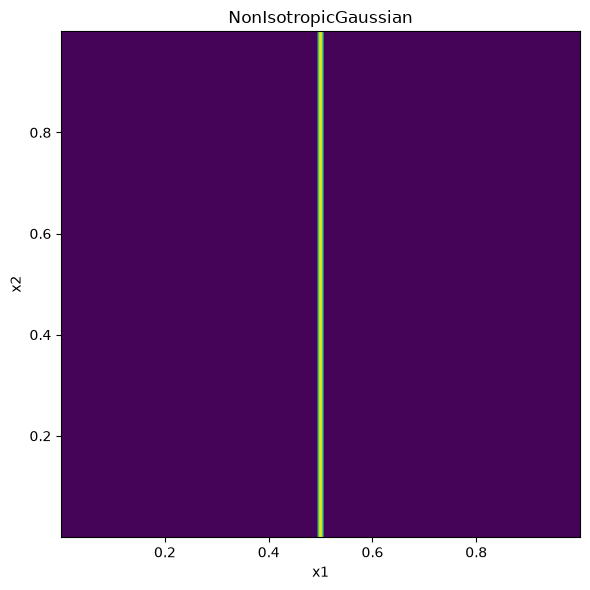

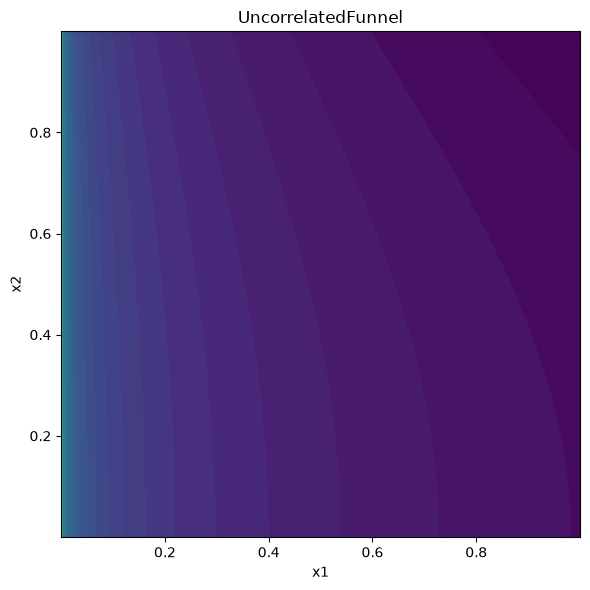

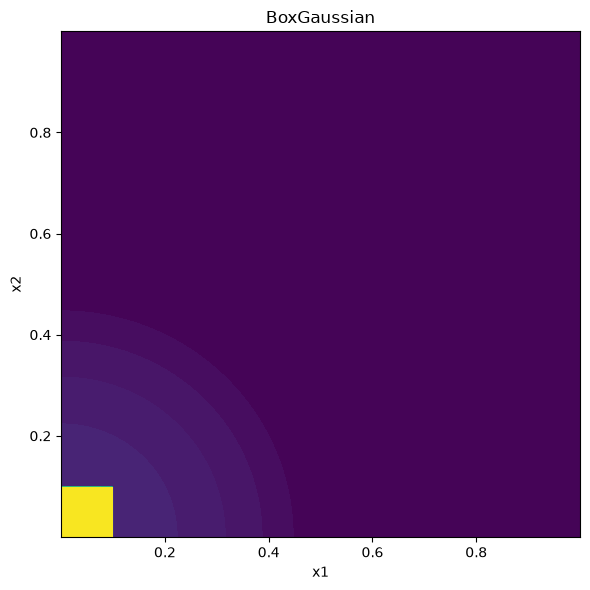

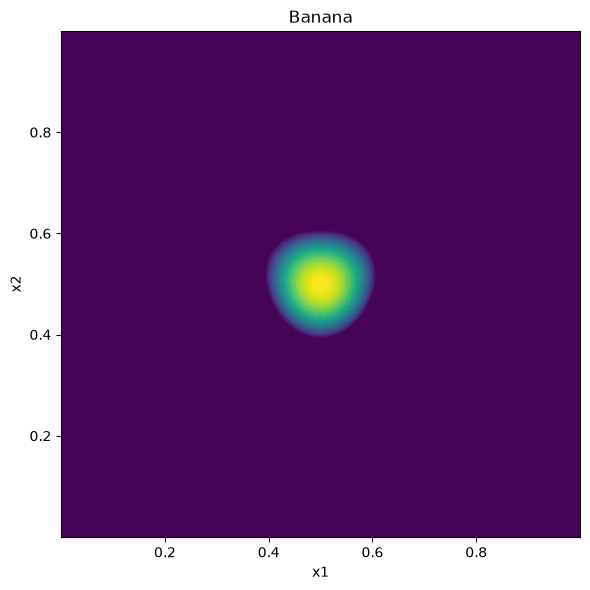

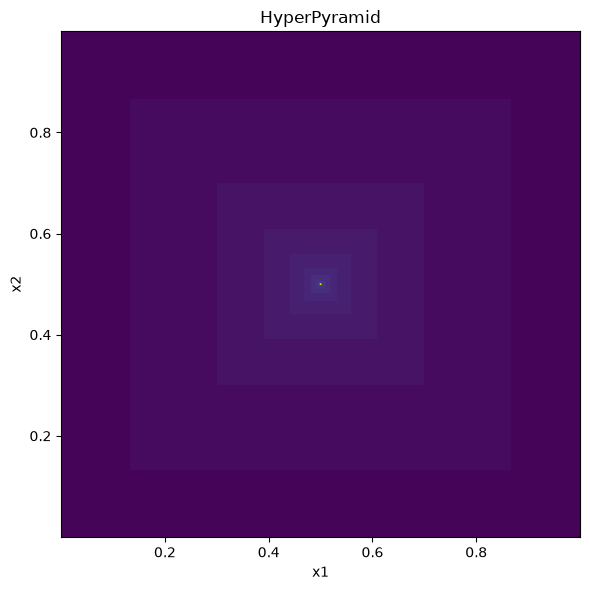

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

from ultranest.perfectns import (
    BananaGaussianLRPS, BoxGaussianLRPS, HyperPyramidLRPS,
    NonIsotropicGaussianLRPS, UncorrelatedFunnelLRPS)

problems = [
    ('NonIsotropicGaussian',
     lambda d: NonIsotropicGaussianLRPS(d)),
    ('UncorrelatedFunnel',
     lambda d: UncorrelatedFunnelLRPS(d, trunc_sigmas=6.0)),
    ('BoxGaussian', lambda d: BoxGaussianLRPS(d)),
    ('Banana', lambda d: BananaGaussianLRPS.standard_problem(d)),
    ('HyperPyramid', lambda d: HyperPyramidLRPS(d)),
]

grid = np.linspace(1e-6, 1 - 1e-6, 501)
X, Y = np.meshgrid(grid, grid)
pts = np.stack([X.flatten(), Y.flatten()], axis=1)

# for the shape display, the banana uses a narrower and more strongly
# curved configuration than the standard problem (sigma=0.1, bend=1,
# whose wide tube the tables below use), to resemble the proportions of
# the narrow Rosenbrock banana
display_overrides = {
    'Banana': lambda d: BananaGaussianLRPS.standard_problem(
        d, sigma=0.02, bend=1.75),
}

for (name, make) in problems:
    fig, ax = plt.subplots(figsize=(6, 6))
    L = display_overrides.get(name, make)(2).loglike(pts).reshape(X.shape)
    vmax = np.percentile(L[np.isfinite(L)], 99)
    ax.contourf(X, Y, np.clip(L, vmax - 10, L.max()), levels=50)
    ax.set_title(name)
    ax.set_xlabel('x1')
    ax.set_ylabel('x2')
    plt.tight_layout()


The gaussian problems are smooth ellipsoids (the NonIsotropicGaussian
strongly anisotropic, the funnel with a curved width profile), the box is
flat with sharp edges, the banana is curved, and the pyramid is
piecewise-linear.

## Analytic lnZ values across dimensionality

`analytic_lnZ()` gives the reference value a nested sampler should
recover. Notes:

* the **banana** value is a 2d numerical integration and raises for
  $d \neq 2$ (marked `NaN`);
* the **funnel** values continue the smooth trend to $\approx -21$ at
  $d=40$; the earlier $-\infty$ entries were a double-precision loss
  in the $\Phi$ difference of the analytic formula (now computed
  through the survival functions, see `UncorrelatedFunnelLRPS.analytic_lnZ`);
* the NonIsotropicGaussian is normalized and its bulk lies inside the
  cube, so its `lnZ` stays at $\approx 0$; the box concentrates its
  probability mass, so its `lnZ` is large and positive.

In [2]:
import pandas as pd

dims = [1, 2, 3, 4, 5, 7, 10, 15, 20, 30, 40]
rows = {}
for name, make in problems:
    vals = []
    for d in dims:
        try:
            vals.append(float(make(d).analytic_lnZ()))
        except Exception:
            vals.append(np.nan)
    rows[name] = vals

df = pd.DataFrame.from_dict(rows, orient='index', columns=dims)
df.index.name = 'problem'
df.round(3)


,1,2,3,4,5,7,10,15,20,30,40
problem,,,,,,,,,,,
NonIsotropicGaussian,0.000,-0.000,-0.000,-0.000,-0.000,-0.000,-0.000,-0.000,-0.000,-0.000,-0.000
UncorrelatedFunnel,-2.871,-5.491,-7.862,-9.983,-11.854,-14.851,-17.630,-19.517,-20.275,-21.000,-21.392
BoxGaussian,97.541,95.083,92.624,90.166,87.707,82.790,75.415,63.122,50.830,26.245,1.660
Banana,NaN,-2.769,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
HyperPyramid,-0.983,-0.988,-0.990,-0.991,-0.991,-0.992,-0.992,-0.992,-0.993,-0.993,-0.993


## Nested sampling with the perfectns exact proposals

The same problems up to $d=10$, computed by nested sampling runs
instead of the analytic formulae: `ReactiveNestedSampler` with
`region_class=PerfectRegion.with_problem(problem)` draws its candidates
from the analytically known enclosing proposal of each problem, so the
usual region-building proposal issues do not apply and the acceptance
rate stays high. The first table shows the nested sampling `lnZ` (200
live points, seed 1 per run), the second the deviation from the
analytic reference above. The columns $d \geq 15$ are omitted: the
nested sampling runs there are orders of magnitude more expensive
(the likelihood constraints shrink to a tiny fraction of the cube).
The banana's analytic value only exists at
$d=2$, so its deviations are `NaN` elsewhere; the wide-tube banana
configuration of the tables is used, not the narrow display one.


In [3]:
import logging
import warnings

from ultranest import ReactiveNestedSampler
from ultranest.perfectns import PerfectRegion

# the per-run logs would flood the output of the ~50 runs below
logging.getLogger('ultranest').disabled = True
logging.getLogger('ultranest.ReactiveNestedSampler').disabled = True

# d >= 15 is omitted: those runs are orders of magnitude more
# expensive (the likelihood constraints shrink to a tiny fraction
# of the cube; the analytic table above covers them)
dims_ns = [1, 2, 3, 4, 5, 7, 10]

rows, deviations = {}, {}
for name, make in problems:
    vals, devs = [], []
    for d in dims_ns:
        try:
            problem = make(d)
            np.random.seed(1)
            with warnings.catch_warnings():
                # the transient "Sampling from region seems inefficient"
                # UserWarning is expected here: the point stack serves
                # proposals drawn for the previous threshold and the
                # refill loop retries; it does not bias the results
                warnings.filterwarnings(
                    'ignore',
                    message='.*Sampling from region seems inefficient.*')
                sampler = ReactiveNestedSampler(
                    problem.paramnames, problem.loglike,
                    transform=problem.transform, vectorized=True)
                result = sampler.run(
                    min_num_live_points=200, frac_remain=0.5,
                    region_class=PerfectRegion.with_problem(problem),
                    show_status=False, viz_callback=None)
            vals.append(float(result['logz']))
            try:
                devs.append(float(result['logz'] - problem.analytic_lnZ()))
            except Exception:
                devs.append(np.nan)
        except Exception:
            vals.append(np.nan)
            devs.append(np.nan)
    rows[name] = vals
    deviations[name] = devs

df_ns = pd.DataFrame.from_dict(rows, orient='index', columns=dims_ns)
df_ns.index.name = 'problem'
df_dev = pd.DataFrame.from_dict(deviations, orient='index', columns=dims_ns)
df_dev.index.name = 'problem'
print('nested sampling lnZ (200 live points, PerfectRegion exact proposals):')
display(df_ns.round(3))
print('deviation from the analytic lnZ:')
df_dev.round(3)


nested sampling lnZ (200 live points, PerfectRegion exact proposals):


,1,2,3,4,5,7,10
problem,,,,,,,
NonIsotropicGaussian,0.230,-0.014,-0.375,0.182,0.190,0.097,-0.090
UncorrelatedFunnel,-2.840,-5.584,-7.888,-9.967,-11.917,-14.633,-17.881
BoxGaussian,97.617,95.127,92.476,90.069,87.375,83.042,75.222
Banana,NaN,-2.774,-3.998,-5.572,-6.817,-9.582,-13.618
HyperPyramid,-0.984,-0.988,-0.990,-0.991,-0.991,-0.992,-0.992


deviation from the analytic lnZ:


,1,2,3,4,5,7,10
problem,,,,,,,
NonIsotropicGaussian,0.230,-0.014,-0.375,0.182,0.190,0.097,-0.090
UncorrelatedFunnel,0.031,-0.093,-0.025,0.016,-0.063,0.218,-0.251
BoxGaussian,0.075,0.044,-0.148,-0.097,-0.332,0.252,-0.193
Banana,NaN,-0.005,NaN,NaN,NaN,NaN,NaN
HyperPyramid,-0.000,-0.000,-0.000,0.000,0.000,0.000,0.000


## Using the problems

Each problem exposes `paramnames`, `transform(u)` and
`loglike(theta)` (vectorized), plus `analytic_lnZ()` and
`make_volume_function()`. They are the standard way to test a nested
sampler end to end: run the sampler and compare its `lnZ` against the
table above.